In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
def append_csv(source_file, target_file):
    source_data = pd.read_csv(source_file, skiprows = 0)
    target_data = pd.read_csv(target_file, skiprows = 1)

    combined_data = pd.concat([source_data, target_data])
    combined_data.to_csv(target_file, index=False)

# Example usage
# source_file = 'RL_mimo_ofdm/PPO_2ue16Nt_buffer/monitor_14.csv'
# target_file = 'RL_mimo_ofdm/PPO_2ue16Nt_buffer/monitor_15.csv'
# append_csv(source_file, target_file)

### Assumptions

- Buffer for $U$ users are $[B_1, \cdots, B_U]$, each with a fixed buffer size.
- First-in first-out principle.
- A longest waiting time of a packet is $T$.
- The arrival probability of packets is i.i.d. and follows Binomial distribution with the arrival rate $P_{d}$. 
- A packet is of size 1. 

- Packet drop:
    - $drop_{l}$: a packet's waiting time is longer than $T$.

    - $drop_{o}$: a user's buffer is full and there is new packet coming.

#### Reward calculation
The reward is calculated as

$r = - (drop_{l} + drop_{o}) - 0.5*(error_{range}>0.2 + error_{speed}>0.2)$

where $drop_{l} \in\{0,1\}$, $drop_{o}\in\{0,1\}$, and the reward of the estimation part is also binary.

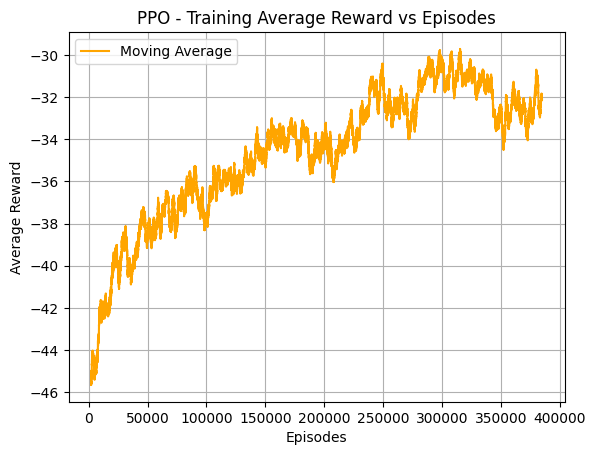

In [25]:


monitor_file = "RL_mimo_ofdm/PPO_2ue16Nt_buffer/monitor_15.csv"
# MONITOR_2 is temporary file for testing. It is still running
monitor_data = pd.read_csv(monitor_file, skiprows=0)

window_size = 2000
moving_average = monitor_data['r'].rolling(window=window_size).mean()

fig, ax = plt.subplots()
ax.plot(moving_average, label='Moving Average', color='orange')
ax.legend()
ax.grid()
ax.set_xlabel('Episodes')
ax.set_ylabel('Average Reward')
ax.set_title('PPO - Training Average Reward vs Episodes')

plt.show()

The entropy loss changes from -22.7 to fluctuating between -0.5 to 0. 

Overall, the model is trained for around 80 hours.

**Benchmark**
- Estimated AoD: The BS estimates the AoDs using MUSIC algorithm based on the reflected echoes. 
Then, the BS best beams to users according to these estimated AoDs.

- Random: One beam is randomly allocated to a user.

**Comparison of reward**
The benchmark of Estimated AoDs is even worse than the begining of the PPO training. 
- Reason: Estimated AoD method only allocates one beam to a user, this will often lead to a bad estimation performance, which is captured by the reward calculation.

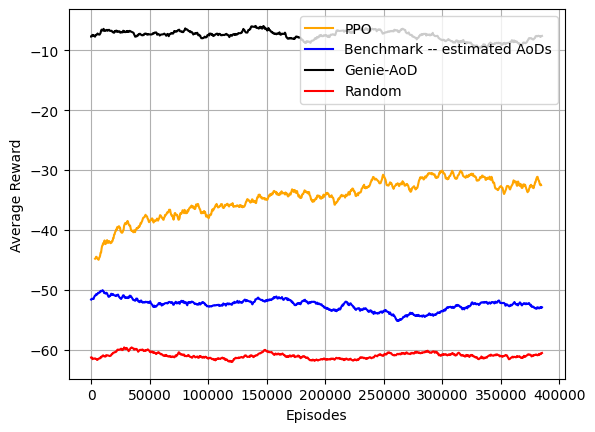

In [52]:
import numpy as np
monitor_file = "RL_mimo_ofdm/PPO_2ue16Nt_buffer/monitor_15.csv"
# MONITOR_95 is temporary file for testing. It is still running
monitor_data = pd.read_csv(monitor_file, skiprows=0)

window_size = 3000
moving_average = monitor_data['r'].rolling(window=window_size).mean()

benchmark_reward = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_buffer/estimated/reward.csv', skiprows=0)
br = benchmark_reward['Reward'].rolling(window = 100).mean()
br_length = len(br.dropna())
selected_values = moving_average[::len(moving_average)//br_length][:(br_length)]

genie_reward = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_buffer/genie/reward.csv', skiprows=0)
gr = genie_reward['Reward'].rolling(window = 100).mean()

random_reward = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_buffer/random/reward.csv', skiprows=0)
rr = random_reward['Reward'].rolling(window = 100).mean()

fig, ax = plt.subplots()
ax.plot( selected_values, label='PPO', color='orange')

ax.plot(np.linspace(0, len(moving_average), br_length), br.dropna(), label='Benchmark -- estimated AoDs', color='blue')
ax.plot(np.linspace(0, len(moving_average), br_length), gr.dropna(), label='Genie-AoD', color='black')
ax.plot(np.linspace(0, len(moving_average), br_length), rr.dropna(), label='Random', color='red')

ax.legend(loc='upper right')
ax.grid()
ax.set_xlabel('Episodes')
ax.set_ylabel('Average Reward')

plt.show()

**Communication -- Latency**

The following figure evaluates the probability of waiting time for a **transmitted** packet for different methods.

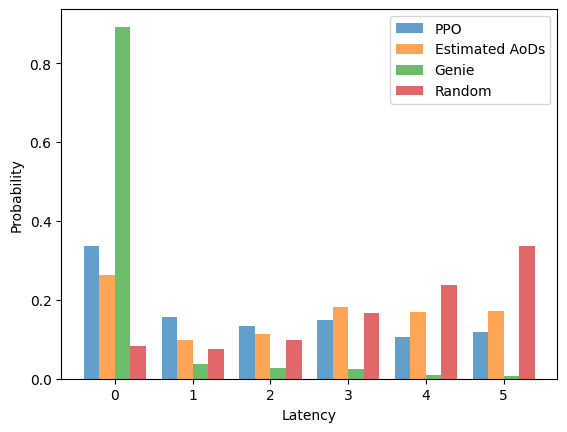

In [53]:
import matplotlib.pyplot as plt
import itertools

fd_trained = 'RL_mimo_ofdm/PPO_2ue16Nt_buffer/trained/'
fd_estimated = 'RL_mimo_ofdm/PPO_2ue16Nt_buffer/estimated/'
fd_random = 'RL_mimo_ofdm/PPO_2ue16Nt_buffer/random/'

latency_t = pd.read_csv(fd_trained + 'latency.csv', skiprows=0)
latency_b = pd.read_csv(fd_estimated + 'latency.csv', skiprows=0)

latency_g = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_buffer/genie/latency.csv', skiprows=0)
latency_r = pd.read_csv(fd_random + 'latency.csv', skiprows=0)

latency_benchmark = list(itertools.chain(*latency_t.values))
latency_trained = list(itertools.chain(*latency_b.values))
latency_genie = list(itertools.chain(*latency_g.values))
latency_random = list(itertools.chain(*latency_r.values))

latency_trained = [x for x in latency_trained if x != -1]
latency_benchmark = [x for x in latency_benchmark if x != -1]
latency_genie = [x for x in latency_genie if x != -1]
latency_random = [x for x in latency_random if x != -1]

#
figure_handle = plt.figure()
ax2 = figure_handle.add_subplot()

counts_trained, bins_trained, patches_trained = ax2.hist(latency_trained, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark, bins_benchmark, patches_benchmark = ax2.hist(latency_benchmark, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie, bins_genie, patches_genie = ax2.hist(latency_genie, bins=range(7), density=True, alpha=0.7, label='Genie')
counts_random, bins_random, patches_random = ax2.hist(latency_random, bins=range(7), density=True, alpha=0.7, label='Random')

bin_centers = 0.5 * (bins_trained[:-1] + bins_trained[1:])

ax2.cla()  # Clear the previous plot
ax2.bar(bin_centers - 0.3, counts_trained, width=0.2, align='center', alpha=0.7, label='PPO')
ax2.bar(bin_centers - 0.1, counts_benchmark, width=0.2, align='center', alpha=0.7, label='Estimated AoDs')
ax2.bar(bin_centers+0.1, counts_genie, width=0.2, align='center', alpha=0.7, label='Genie')
ax2.bar(bin_centers+0.3, counts_random, width=0.2, align='center', alpha=0.7, label='Random')

ax2.set_xticks(bin_centers)

ax2.set_xticks(bin_centers)
ax2.set_xticklabels(range(6))
ax2.set_xlabel('Latency')
ax2.set_ylabel('Probability')
ax2.legend()


**Communication -- spectral efficiency**

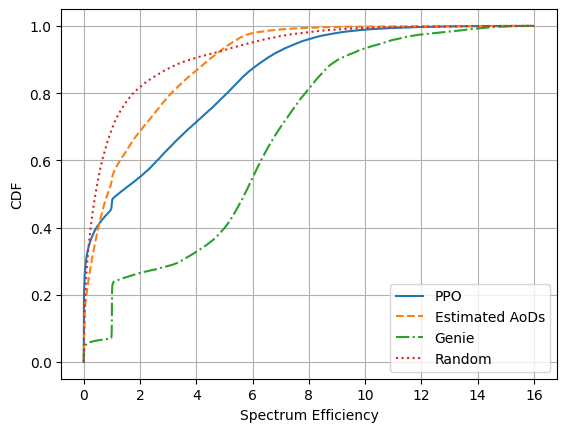

In [68]:
se_trained = pd.read_csv(fd_trained + 'SE.csv', skiprows=0)
se_benchmark = pd.read_csv(fd_estimated + 'SE.csv', skiprows=0)
se_genie = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_buffer/genie/SE.csv', skiprows=0)
se_random = pd.read_csv(fd_random + 'SE.csv', skiprows=0)

spectrum_efficiency_trained = list(itertools.chain(*se_trained.values))
spectrum_efficiency_benchmark = list(itertools.chain(*se_benchmark.values))
spectrum_efficiency_genie = list(itertools.chain(*se_genie.values))
spectrum_efficiency_random = list(itertools.chain(*se_random.values))

figure_handle = plt.figure()
ax = figure_handle.add_subplot()
se_cdf = np.sort(spectrum_efficiency_trained)
yvals = np.arange(len(se_cdf))/float(len(se_cdf)-1)
ax.plot(se_cdf, yvals, '-', label='PPO')

se_cdf = np.sort(spectrum_efficiency_benchmark)
yvals = np.arange(len(se_cdf))/float(len(se_cdf)-1)
ax.plot(se_cdf, yvals, '--', label='Estimated AoDs')

se_cdf = np.sort(spectrum_efficiency_genie)
yvals = np.arange(len(se_cdf))/float(len(se_cdf)-1)
ax.plot(se_cdf, yvals, '-.', label='Genie')

se_cdf = np.sort(spectrum_efficiency_random)
yvals = np.arange(len(se_cdf))/float(len(se_cdf)-1)
ax.plot(se_cdf, yvals, ':', label='Random')

ax.set_xlabel('Spectrum Efficiency')
ax.set_ylabel('CDF')
ax.legend()
ax.grid()

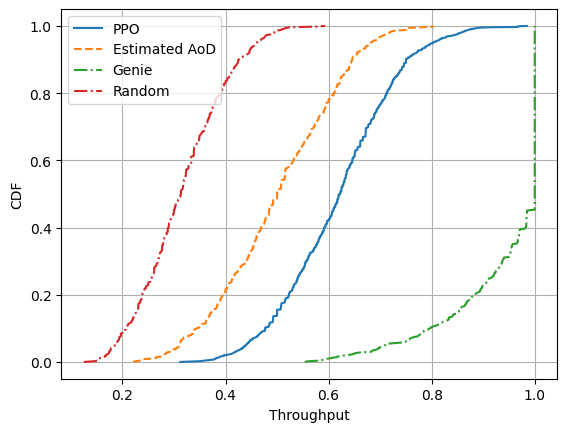

In [67]:
#### Throughput CDF ####
throughput_t = pd.read_csv(fd_trained + 'throughput.csv', skiprows=0)
throughput_b = pd.read_csv(fd_estimated + 'throughput.csv', skiprows=0)
throughput_g = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_buffer/genie/throughput.csv', skiprows=0)
throughput_r = pd.read_csv(fd_random + 'throughput.csv', skiprows=0)

figure_handle = plt.figure()
ax = figure_handle.add_subplot()

thp_cdf = np.sort(throughput_t['Throughput'])
yvals = np.arange(len(thp_cdf))/float(len(thp_cdf)-1)
ax.plot(thp_cdf, yvals, '-', label='PPO')

thp_cdf = np.sort(throughput_b['Throughput'])
yvals = np.arange(len(thp_cdf))/float(len(thp_cdf)-1)
ax.plot(thp_cdf, yvals, '--', label='Estimated AoD')

thp_cdf = np.sort(throughput_g['Throughput'])
yvals = np.arange(len(thp_cdf))/float(len(thp_cdf)-1)
ax.plot(thp_cdf, yvals, '-.', label='Genie')

thp_cdf = np.sort(throughput_r['Throughput'])
yvals = np.arange(len(thp_cdf))/float(len(thp_cdf)-1)
ax.plot(thp_cdf, yvals, '-.', label='Random')

ax.legend()
ax.set_xlabel('Throughput')
ax.set_ylabel('CDF')
ax.grid()

**Estimation performance**
The estimation performance of range, speed, and angle are affected by the number of subcarriers, the number of OFDM symbols, and the number of antennas,respectively.

Let us define the range bin, speed bin and angle bin as

$$
\Delta_d = \frac{c}{2N_c \Delta f}, ~~ \Delta_v = \frac{c}{2f_c N_s T}, ~~ \Delta_a = \frac{\pi}{N_r}
$$.

Therefore, the normalized error are defined with respect to these bins.

For estimation of range and speed (the following two figures), we can observe that PPO performans better compared to the two benchmarks.

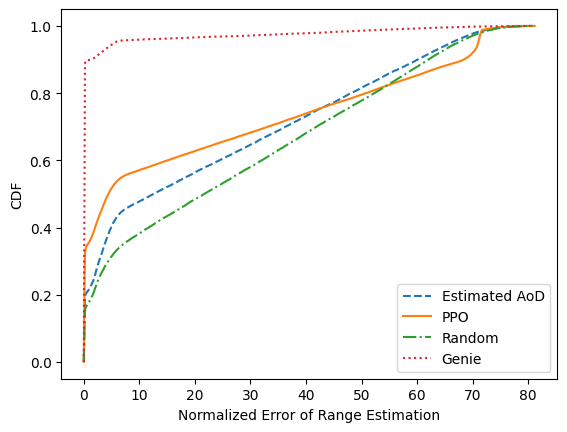

In [66]:
#### CDF of estimation error ####
# range estimation
er_t = pd.read_csv(fd_trained + 'nmseR_allsteps.csv', skiprows=1)
er_b = pd.read_csv(fd_estimated + 'nmseR_allsteps.csv', skiprows=1)
er_r = pd.read_csv(fd_random + 'nmseR_allsteps.csv', skiprows=1)
er_g = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_buffer/genie/nmseR_allsteps.csv', skiprows=1)

figure_handle = plt.figure()
ax3 = figure_handle.add_subplot()
er_benchmark = np.array(er_b)
er_trained = np.array(er_t)
er_random = np.array(er_r)
er_genie = np.array(er_g)

# for u in range(1,2):
    
#     temp = er_benchmark[:,u]
#     er_cdf = np.sort(temp)
#     yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
#     ax3.plot(er_cdf, yvals, '--', label='Benchmark - UE %d'%u)

#     temp = er_trained[:,u]
#     er_cdf = np.sort(temp)
#     yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
#     ax3.plot(er_cdf, yvals, '-', label='PPO - UE %d'%u)

#     temp = er_random[:,u]
#     er_cdf = np.sort(temp)
#     yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
#     ax3.plot(er_cdf, yvals, '-.', label='Random - UE %d'%u)

#     temp = er_genie[:,u]
#     er_cdf = np.sort(temp)
#     yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
#     ax3.plot(er_cdf, yvals, ':', label='Genie - UE %d'%u)
    
temp = er_benchmark.flatten()
er_cdf = np.sort(temp)
yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
ax3.plot(er_cdf, yvals, '--', label='Estimated AoD')

temp = er_trained.flatten()
er_cdf = np.sort(temp)
yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
ax3.plot(er_cdf, yvals, '-', label='PPO')

temp = er_random.flatten()
er_cdf = np.sort(temp)
yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
ax3.plot(er_cdf, yvals, '-.', label='Random')

temp = er_genie.flatten()
er_cdf = np.sort(temp)
yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
ax3.plot(er_cdf, yvals, ':', label='Genie')

ax3.set_xlabel('Normalized Error of Range Estimation')
ax3.set_ylabel('CDF')
ax3.legend()
plt.show()



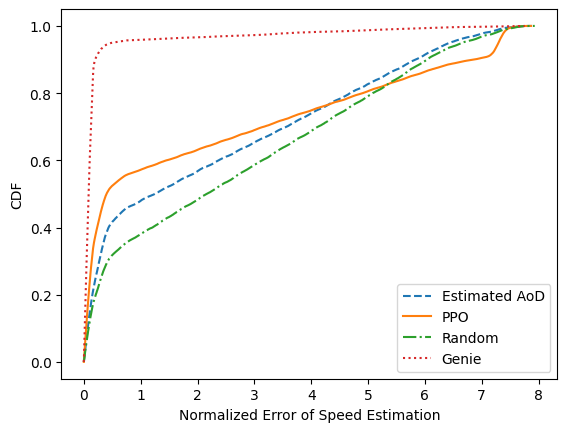

In [65]:
# CDF of speed estimation error
ev_t = pd.read_csv(fd_trained + 'nmseV_allsteps.csv', skiprows=1)
ev_b = pd.read_csv(fd_estimated + 'nmseV_allsteps.csv', skiprows=1)
ev_r = pd.read_csv(fd_random + 'nmseV_allsteps.csv', skiprows=1)
ev_g = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_buffer/genie/nmseV_allsteps.csv', skiprows=1)

ev_benchmark = np.array(ev_b)
ev_trained = np.array(ev_t)
ev_random = np.array(ev_r)
ev_genie = np.array(ev_g)

figure_handle = plt.figure()
ax4 = figure_handle.add_subplot()
# for u in range(1,2):
#     temp = ev_benchmark[:,u]
#     ev_cdf = np.sort(temp)
#     yvals = np.arange(len(ev_cdf))/float(len(ev_cdf)-1)
#     ax4.plot(ev_cdf, yvals, '--', label='Benchmark - UE %d'%u)

#     temp = ev_trained[:,u]
#     ev_cdf = np.sort(temp)
#     yvals = np.arange(len(ev_cdf))/float(len(ev_cdf)-1)
#     ax4.plot(ev_cdf, yvals, '-', label='PPO - UE %d'%u)

#     temp = ev_random[:,u]
#     ev_cdf = np.sort(temp)
#     yvals = np.arange(len(ev_cdf))/float(len(ev_cdf)-1)
#     ax4.plot(ev_cdf, yvals, '-.', label='Random - UE %d'%u)

#     temp = ev_genie[:,u]
#     ev_cdf = np.sort(temp)
#     yvals = np.arange(len(ev_cdf))/float(len(ev_cdf)-1)
#     ax4.plot(ev_cdf, yvals, ':', label='Genie - UE %d'%u)

temp = ev_benchmark.flatten()
ev_cdf = np.sort(temp)
yvals = np.arange(len(ev_cdf))/float(len(ev_cdf)-1)
ax4.plot(ev_cdf, yvals, '--', label='Estimated AoD')

temp = ev_trained.flatten()
ev_cdf = np.sort(temp)
yvals = np.arange(len(ev_cdf))/float(len(ev_cdf)-1)
ax4.plot(ev_cdf, yvals, '-', label='PPO')

temp = ev_random.flatten()
ev_cdf = np.sort(temp)
yvals = np.arange(len(ev_cdf))/float(len(ev_cdf)-1)
ax4.plot(ev_cdf, yvals, '-.', label='Random')

temp = ev_genie.flatten()
ev_cdf = np.sort(temp)
yvals = np.arange(len(ev_cdf))/float(len(ev_cdf)-1)
ax4.plot(ev_cdf, yvals, ':', label='Genie')
    
ax4.set_xlabel('Normalized Error of Speed Estimation')
ax4.set_ylabel('CDF')
ax4.legend()
plt.show()

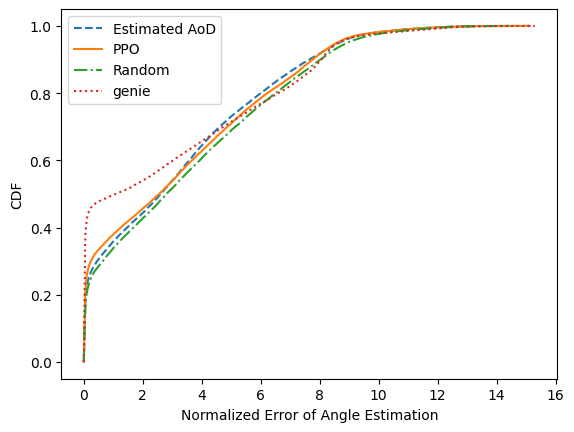

In [64]:
# CDF of angle estimation error
ea_t = pd.read_csv(fd_trained + 'nmseA_allsteps.csv', skiprows=1)
ea_b = pd.read_csv(fd_estimated + 'nmseA_allsteps.csv', skiprows=1)
ea_r = pd.read_csv(fd_random + 'nmseA_allsteps.csv', skiprows=1)
ea_g = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_buffer/genie/nmseA_allsteps.csv', skiprows=1)

ea_benchmark = np.array(ea_b)
ea_trained = np.array(ea_t)
ea_random = np.array(ea_r)
ea_genie = np.array(ea_g)

figure_handle = plt.figure()
ax4 = figure_handle.add_subplot()
# for u in range(0,1):
    # temp = ea_benchmark[:,u]
    # ea_cdf = np.sort(temp)
    # yvals = np.arange(len(ea_cdf))/float(len(ea_cdf)-1)
    # ax4.plot(ea_cdf, yvals, '--', label='Estimated AoD - UE %d'%u)

    # temp = ea_trained[:,u]
    # ea_cdf = np.sort(temp)
    # yvals = np.arange(len(ea_cdf))/float(len(ea_cdf)-1)
    # ax4.plot(ea_cdf, yvals, '-', label='PPO - UE %d'%u)

    # temp = ea_random[:,u]
    # ea_cdf = np.sort(temp)
    # yvals = np.arange(len(ea_cdf))/float(len(ea_cdf)-1)
    # ax4.plot(ea_cdf, yvals, '-.', label='Random - UE %d'%u)

    # temp = ea_genie[:,u]
    # ea_cdf = np.sort(temp)
    # yvals = np.arange(len(ea_cdf))/float(len(ea_cdf)-1)
    # ax4.plot(ea_cdf, yvals, ':', label='Genie - UE %d'%u)
    
temp = ea_benchmark.flatten()
ea_cdf = np.sort(temp)
yvals = np.arange(len(ea_cdf))/float(len(ea_cdf)-1)
ax4.plot(ea_cdf, yvals, '--', label='Estimated AoD')

temp = ea_trained.flatten()
ea_cdf = np.sort(temp)
yvals = np.arange(len(ea_cdf))/float(len(ea_cdf)-1)
ax4.plot(ea_cdf, yvals, '-', label='PPO')

temp = ea_random.flatten()
ea_cdf = np.sort(temp)
yvals = np.arange(len(ea_cdf))/float(len(ea_cdf)-1)
ax4.plot(ea_cdf, yvals, '-.', label='Random')

temp = ea_genie.flatten()
ea_cdf = np.sort(temp)
yvals = np.arange(len(ea_cdf))/float(len(ea_cdf)-1)
ax4.plot(ea_cdf, yvals, ':', label = 'genie')

ax4.set_xlabel('Normalized Error of Angle Estimation')
ax4.set_ylabel('CDF')
ax4.legend()
plt.show()